# Conditional VAE with Discriminator Loss (cVAE-GAN)

**Hypothesis**

> Adding a discriminator term to the loss function of a Conditional VAE during training increases the sharpness of the reconstructed images.

Training two models on a custom 20×20 MNIST dataset:
1. **Baseline cVAE** - A standard Conditional Variational Autoencoder trained with MSE reconstruction loss and KL-Divergence.
2. **Modified cVAE** - The same architecture, but trained with an additional adversarial discriminator loss to encourage sharper, more realistic outputs.

Both models share identical encoder/decoder architectures with a latent dimension of **z = 7**, ensuring a fair comparison.

## Setup and Imports

Import all required libraries and model definitions. The neural network architectures (`cVAE`, `cDiscriminator`) and the shared loss function (`compute_vae_loss`) are centralised in `models.py` to guarantee structural parity between training and evaluation.

In [1]:
from torch.utils.data import DataLoader, TensorDataset
from torchvision.utils import make_grid
from sklearn.model_selection import train_test_split
from tqdm import tqdm
import copy
import matplotlib.pyplot as plt
import numpy as np
import sys
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import os
import pandas as pd
from models import cVAE, cDiscriminator, compute_vae_loss

# Fix random seeds for reproducibility
seed = 42
torch.manual_seed(seed)
np.random.seed(seed)
torch.cuda.manual_seed_all(seed)

# Define parameters
z_dim = 7          # Number of latent dimensions 
num_classes = 10   # Number of MNIST digit classes (0-9)
batch_size = 1000  # Number of samples processed in each batch
nb_epoch = 200     # Maximum number of training epochs
patience = 10       # Stop training after 5 epochs without validation loss improvement

# Use GPU when available; otherwise use CPU
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

Using device: cuda:0


## Data Loading

Loading the custom MNIST dataset from the `mnist_custom/` directory. This dataset contains 20×20 pixel handwritten digits (cropped from the standard 28×28 MNIST). The data is split into training and testing sets, with a batch size of 1000.

In [2]:
# Load the provided custom MNIST dataset
data_custom = torch.load('mnist_custom.pt', weights_only=False)

# Check the shape of the training and test data
print("Train images:", data_custom['train_images'].shape)
print("Train labels:", data_custom['train_labels'].shape)
print("Test images:", data_custom['test_images'].shape)
print("Test labels:", data_custom['test_labels'].shape)

Train images: torch.Size([60000, 1, 20, 20])
Train labels: torch.Size([60000])
Test images: torch.Size([10000, 1, 20, 20])
Test labels: torch.Size([10000])


In [3]:
# Split the original training data into 90% training and 10% validation
train_idx, val_idx = train_test_split(np.arange(len(data_custom['train_labels'])), test_size=0.1, random_state=seed, stratify=data_custom['train_labels'].numpy())

# Save the split indices for reproducibility
os.makedirs('assets', exist_ok=True)
np.save('assets/train_idx.npy', train_idx)
np.save('assets/val_idx.npy', val_idx)

# Create training, validation and test datasets
train_dataset = TensorDataset(data_custom['train_images'][train_idx], data_custom['train_labels'][train_idx])
val_dataset = TensorDataset(data_custom['train_images'][val_idx], data_custom['train_labels'][val_idx])
test_dataset = TensorDataset(data_custom['test_images'], data_custom['test_labels'])

# Check the size of each dataset
print(f"Train: {len(train_dataset)}")
print(f"Validation: {len(val_dataset)}")
print(f"Test: {len(test_dataset)}")

Train: 54000
Validation: 6000
Test: 10000


In [4]:
# Create data loaders for training, validation and test sets
train_dataloader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=0)
val_dataloader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=0)
test_dataloader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=0)

# Convert digit labels into one-hot encoded conditions and move each batch to the selected device
def get_batch(batch, device, f_train=True, num_classes=10):
    x = batch[0].to(device)
    cond = batch[1].to(device)
    cond = F.one_hot(cond, num_classes=num_classes).float()
    return x, cond

## Dataset Inspection

Let's visually inspect a sample of 10 images from the dataset to verify the data is loaded correctly and understand the visual characteristics of the 20×20 digit images.

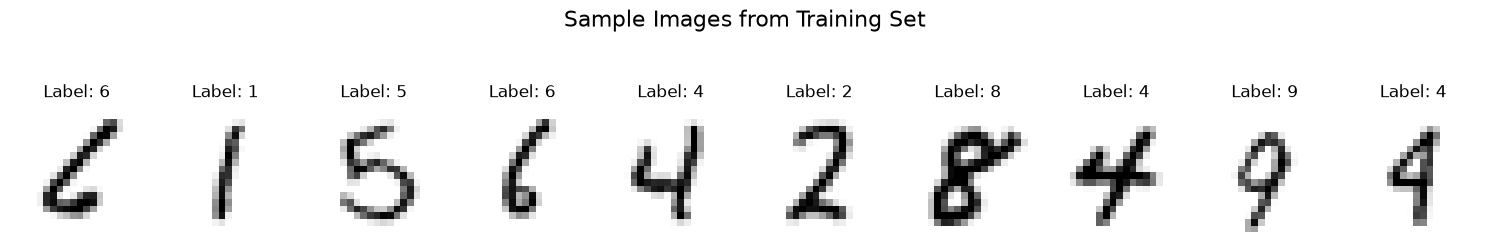

In [5]:
# Visualise sample images from the training set
batch_x, batch_y = next(iter(train_dataloader))

fig, axes = plt.subplots(1, 10, figsize=(15, 3))
for i in range(10):
    axes[i].imshow(batch_x[i].squeeze(), cmap='gray')
    axes[i].set_title(f'Label: {batch_y[i].item()}')
    axes[i].axis('off')

plt.suptitle('Sample Images from Training Set', fontsize=16)
plt.tight_layout()
plt.show()

In [6]:
# Check the class distribution across training, validation and test sets
train_labels = data_custom['train_labels'][train_idx]
val_labels = data_custom['train_labels'][val_idx]
test_labels = data_custom['test_labels']

distribution = pd.DataFrame({
    'Class': range(num_classes),
    'Train Count': torch.bincount(train_labels, minlength=num_classes).numpy(),
    'Train %': torch.bincount(train_labels, minlength=num_classes).numpy() / len(train_labels) * 100,
    'Validation Count': torch.bincount(val_labels, minlength=num_classes).numpy(),
    'Validation %': torch.bincount(val_labels, minlength=num_classes).numpy() / len(val_labels) * 100,
    'Test Count': torch.bincount(test_labels, minlength=num_classes).numpy(),
    'Test %': torch.bincount(test_labels, minlength=num_classes).numpy() / len(test_labels) * 100
})

# Save the dataset distribution for later analysis and reporting
distribution.to_csv('assets/dataset_distribution.csv', index=False)

# Display percentages to two decimal places
distribution.style.format({
    'Train %': '{:.2f}%',
    'Validation %': '{:.2f}%',
    'Test %': '{:.2f}%'
})

,Class,Train Count,Train %,Validation Count,Validation %,Test Count,Test %
0,0,5331,9.87%,592,9.87%,980,9.80%
1,1,6068,11.24%,674,11.23%,1135,11.35%
2,2,5362,9.93%,596,9.93%,1032,10.32%
3,3,5518,10.22%,613,10.22%,1010,10.10%
4,4,5258,9.74%,584,9.73%,982,9.82%
5,5,4879,9.04%,542,9.03%,892,8.92%
6,6,5326,9.86%,592,9.87%,958,9.58%
7,7,5638,10.44%,627,10.45%,1028,10.28%
8,8,5266,9.75%,585,9.75%,974,9.74%
9,9,5354,9.91%,595,9.92%,1009,10.09%


## 1. Baseline cVAE Training

### Architecture
The baseline model is a standard Conditional VAE consisting of:
- **Encoder**: Takes a flattened 20×20 image concatenated with a one-hot class label and maps it to a latent distribution (μ, log σ²) of dimension z=7.
- **Decoder**: Takes a sampled latent vector z concatenated with the class label and reconstructs the 20×20 image.

### Loss Function
$$\mathcal{L}_{VAE} = \text{MSE}(x, \hat{x}_z) + \beta \cdot \text{KL}(z \| p(z))$$

Where β = 0.1 balances reconstruction fidelity against latent space regularisation. The MSE reconstruction loss is scaled by 100 to increase its relative contribution to the total loss.

### Training Strategy
- **Optimiser**: AdamW with lr=0.001 and betas=(0.75, 0.99)
- **Early stopping**: Patience of 5 epochs based on validation loss
- **Best model**: Weights from the epoch with the lowest validation loss are saved

In [7]:
# Reset random seeds before baseline model training
torch.manual_seed(seed)
np.random.seed(seed)
torch.cuda.manual_seed_all(seed)

# Ensure deterministic GPU operations
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
torch.use_deterministic_algorithms(True)

# Create the baseline conditional VAE model
base_vae = cVAE(z_dim=z_dim, num_classes=num_classes).to(device)

# Define the optimizer for baseline cVAE training
opt_base = optim.AdamW(base_vae.parameters(), lr=0.001, eps=1e-5, fused=False, betas=(0.75, 0.99))

print(base_vae)
print("\n---total number of parameters:")
Nparams = sum(p.numel() for p in base_vae.parameters())
print(Nparams)
print("---total number of trainable parameters:")
Nparams_train = sum(p.numel() for p in base_vae.parameters() if p.requires_grad)
print(Nparams_train)
print()

cVAE(
  (encoder): cEncoder(
    (encoder_backbone): Sequential(
      (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
      (1): ReLU()
      (2): Conv2d(16, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
      (3): ReLU()
      (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
      (5): ReLU()
      (6): Conv2d(64, 256, kernel_size=(3, 3), stride=(1, 1))
      (7): ReLU()
      (8): Flatten(start_dim=1, end_dim=-1)
    )
    (encoder_head): Linear(in_features=266, out_features=14, bias=True)
  )
  (decoder): cDecoder(
    (decoder_input): Sequential(
      (0): Linear(in_features=17, out_features=256, bias=True)
      (1): ReLU()
    )
    (decoder_backbone): Sequential(
      (0): Unflatten(dim=1, unflattened_size=(256, 1, 1))
      (1): ConvTranspose2d(256, 64, kernel_size=(3, 3), stride=(1, 1))
      (2): ReLU()
      (3): ConvTranspose2d(64, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
      (4): ReLU()
      (5): Conv

In [8]:
# Initialise loss tracking and early stopping variables for the baseline cVAE
base_train_losses = []
base_val_losses = []

best_base_val_loss = float('inf')
best_base_epoch = 0
best_base_state = None
base_patience_counter = 0

# Train the baseline cVAE and monitor validation loss
for epoch in range(nb_epoch):
    base_vae.train()
    train_loss = 0.0

    for batch in tqdm(train_dataloader, desc=f"Epoch {epoch+1}/{nb_epoch} - Train"):
        x, cond = get_batch(batch, device)

        opt_base.zero_grad()

        x_hat, mu, logvar = base_vae(x, cond)
        loss, _, _ = compute_vae_loss(x, x_hat, mu, logvar)

        loss.backward()
        opt_base.step()

        train_loss += loss.item()

    train_loss /= len(train_dataloader)

    # Evaluate the model on the validation set
    base_vae.eval()
    val_loss = 0.0

    with torch.no_grad():
        for batch in val_dataloader:
            x, cond = get_batch(batch, device, f_train=False)

            mu, logvar = base_vae.encode(x, cond)
            x_hat = base_vae.decode(mu, cond)

            loss, _, _ = compute_vae_loss(x, x_hat, mu, logvar)
            val_loss += loss.item()

    val_loss /= len(val_dataloader)

    base_train_losses.append(train_loss)
    base_val_losses.append(val_loss)

    print(f"Epoch {epoch+1}: Train Loss = {train_loss:.4f}, Validation Loss = {val_loss:.4f}")

    # Save the best model state based on validation loss
    if val_loss < best_base_val_loss:
        best_base_val_loss = val_loss
        best_base_epoch = epoch + 1
        best_base_state = copy.deepcopy(base_vae.state_dict())
        base_patience_counter = 0
    else:
        base_patience_counter += 1

    # Stop training when validation loss does not improve
    if base_patience_counter >= patience:
        print(f"Early stopping at epoch {epoch+1}")
        break
        
# Report the best epoch selected using validation loss
print(f"Best epoch: {best_base_epoch}")
print(f"Best validation loss: {best_base_val_loss:.4f}")

# Save the baseline training history
np.save('assets/base_train_losses.npy', np.array(base_train_losses))
np.save('assets/base_val_losses.npy', np.array(base_val_losses))

Epoch 1/200 - Train: 100%|██████████| 54/54 [00:01<00:00, 52.83it/s]


Epoch 1: Train Loss = 9.5266, Validation Loss = 6.0737


Epoch 2/200 - Train: 100%|██████████| 54/54 [00:00<00:00, 77.53it/s]


Epoch 2: Train Loss = 5.5494, Validation Loss = 5.1225


Epoch 3/200 - Train: 100%|██████████| 54/54 [00:00<00:00, 77.36it/s]


Epoch 3: Train Loss = 4.8201, Validation Loss = 4.3277


... (260 outputs left out)

Epoch 134/200 - Train: 100%|██████████| 54/54 [00:00<00:00, 77.16it/s]


Epoch 134: Train Loss = 2.1882, Validation Loss = 1.9217


Epoch 135/200 - Train: 100%|██████████| 54/54 [00:00<00:00, 62.81it/s]


Epoch 135: Train Loss = 2.1854, Validation Loss = 1.9400
Early stopping at epoch 135
Best epoch: 125
Best validation loss: 1.9204


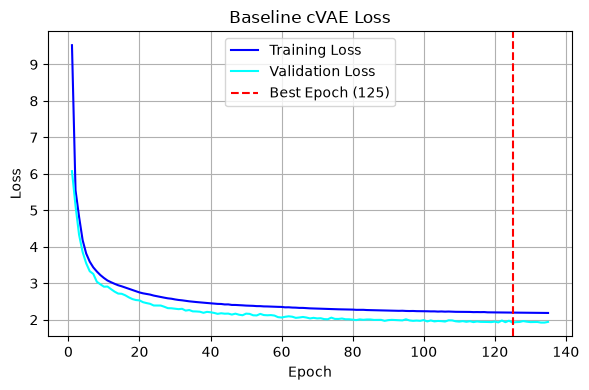

In [9]:
# Plot the baseline cVAE training and validation loss
epochs = np.arange(1, len(base_train_losses) + 1)

plt.figure(figsize=(6, 4))
plt.plot(epochs, base_train_losses, label='Training Loss', color='blue')
plt.plot(epochs, base_val_losses, label='Validation Loss', color='cyan')
plt.axvline(x=best_base_epoch, color='red', linestyle='--', label=f'Best Epoch ({best_base_epoch})')

plt.title('Baseline cVAE Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig('assets/base_vae_loss.png', dpi=300, bbox_inches='tight')
plt.show()

## 2. Modified cVAE Training (with Discriminator Loss)

### Architecture Extension
The baseline cVAE is extended by introducing a **Conditional Discriminator**. The discriminator is conditioned on the digit class and is trained to distinguish between real images and images reconstructed by the cVAE. The discriminator-based loss is then incorporated into the cVAE training process to investigate whether it improves the sharpness of the reconstructed images.

### Loss Functions

The modified training process uses three loss components. In the following formulation, $D(x)$ represents the discriminator's estimated probability that an input image is **real**.

**Generator Loss** - Encourages reconstructed images to be classified as real by the discriminator:

$$
\mathcal{L}_G
=
-\mathbb{E}_z[\log D(G(z))]
$$

**Discriminator Loss** - Trains the discriminator to classify real images as real and reconstructed images as fake:

$$
\mathcal{L}_D
=
-\left(
\mathbb{E}_x[\log D(x)]
+
\mathbb{E}_z[\log(1-D(G(z)))]
\right)
$$

These objectives are implemented using Binary Cross Entropy, where real images are assigned a target of 1 and reconstructed images are assigned a target of 0:

$$
\mathcal{L}^{BCE}_D
=
\mathrm{BCE}(D(x),1)
+
\mathrm{BCE}(D(G(z)),0)
$$

$$
\mathcal{L}^{BCE}_G
=
\mathrm{BCE}(D(G(z)),1)
$$

The negative sign in the discriminator loss converts the original maximisation objective into an equivalent minimisation objective, allowing it to be optimised using gradient descent. In the implementation, `BCEWithLogitsLoss` is used, which combines the sigmoid operation and binary cross-entropy in a numerically stable form.

**VAE Loss** - Retains the reconstruction and KL divergence components of the baseline cVAE:

$$
\mathcal{L}_{VAE}
=
\mathrm{MSE}(x,x_z)
+
\beta\,\mathrm{KL}(z\|p(z))
$$

The modified cVAE objective is:

$$
\mathcal{L}_{modified}
=
\mathcal{L}_{VAE}
+
\mathcal{L}^{BCE}_G
$$

### Training Strategy
- The **discriminator** is trained to distinguish between real and reconstructed images by minimising $\mathcal{L}^{BCE}_D$.
- The **cVAE** is trained using the original VAE loss together with the generator adversarial loss.
- During discriminator training, reconstructed images are detached from the cVAE computation graph so that only the discriminator is updated.
- The same **training and validation split** as the baseline model is used for a comparable experiment.
- **Validation performance** is monitored to assess convergence and select the best training epoch.

In [10]:
# Ensure deterministic GPU operations
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
torch.use_deterministic_algorithms(True)

# Create the modified cVAE
torch.manual_seed(seed)
np.random.seed(seed)
torch.cuda.manual_seed_all(seed)
modified_vae = cVAE(z_dim=z_dim, num_classes=num_classes).to(device)

# Create the discriminator
torch.manual_seed(seed)
np.random.seed(seed)
torch.cuda.manual_seed_all(seed)
discriminator = cDiscriminator(num_classes=num_classes).to(device)

# Define optimizers for the modified cVAE and discriminator
opt_modified = optim.AdamW(modified_vae.parameters(), lr=0.001, eps=1e-5, fused=False, betas=(0.75, 0.99))
opt_discriminator = optim.AdamW(discriminator.parameters(), lr=0.001, eps=1e-5, fused=False, betas=(0.75, 0.99))

In [11]:
# Display the modified cVAE architecture and parameter counts
print(modified_vae)
print("\n---total number of parameters:")
Nparams = sum(p.numel() for p in modified_vae.parameters())
print(Nparams)
print("---total number of trainable parameters:")
Nparams_train = sum(p.numel() for p in modified_vae.parameters() if p.requires_grad)
print(Nparams_train)
print()

# Display the discriminator architecture and parameter counts
print(discriminator)
print("\n---total number of parameters:")
Nparams = sum(p.numel() for p in discriminator.parameters())
print(Nparams)
print("---total number of trainable parameters:")
Nparams_train = sum(p.numel() for p in discriminator.parameters() if p.requires_grad)
print(Nparams_train)
print()

cVAE(
  (encoder): cEncoder(
    (encoder_backbone): Sequential(
      (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
      (1): ReLU()
      (2): Conv2d(16, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
      (3): ReLU()
      (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
      (5): ReLU()
      (6): Conv2d(64, 256, kernel_size=(3, 3), stride=(1, 1))
      (7): ReLU()
      (8): Flatten(start_dim=1, end_dim=-1)
    )
    (encoder_head): Linear(in_features=266, out_features=14, bias=True)
  )
  (decoder): cDecoder(
    (decoder_input): Sequential(
      (0): Linear(in_features=17, out_features=256, bias=True)
      (1): ReLU()
    )
    (decoder_backbone): Sequential(
      (0): Unflatten(dim=1, unflattened_size=(256, 1, 1))
      (1): ConvTranspose2d(256, 64, kernel_size=(3, 3), stride=(1, 1))
      (2): ReLU()
      (3): ConvTranspose2d(64, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
      (4): ReLU()
      (5): Conv

In [12]:
# Initialise loss tracking and early stopping variables for the modified cVAE
modified_train_losses = []
modified_val_losses = []
discriminator_train_losses = []
discriminator_train_acc = []

best_modified_val_loss = float('inf')
best_modified_epoch = 0
modified_patience_counter = 0

# Define the adversarial loss
adversarial_loss = nn.BCEWithLogitsLoss()

In [13]:
# Train the modified cVAE with the discriminator-based loss
for epoch in range(nb_epoch):
    modified_vae.train()
    discriminator.train()

    train_loss = 0.0
    discriminator_loss = 0.0
    discriminator_correct = 0
    discriminator_total = 0

    for batch in tqdm(train_dataloader, desc=f"Epoch {epoch+1}/{nb_epoch} - Train"):
        x, cond = get_batch(batch, device)

        # Generate reconstructed images
        x_hat, mu, logvar = modified_vae(x, cond)

        # Train the discriminator
        real_pred = discriminator(x, cond)
        fake_pred = discriminator(x_hat.detach(), cond)

        d_loss_real = adversarial_loss(real_pred, torch.ones_like(real_pred))
        d_loss_fake = adversarial_loss(fake_pred, torch.zeros_like(fake_pred))
        d_loss = d_loss_real + d_loss_fake

        # Track discriminator classification accuracy
        discriminator_correct += (real_pred >= 0).sum().item()
        discriminator_correct += (fake_pred < 0).sum().item()
        discriminator_total += real_pred.numel() + fake_pred.numel()

        opt_discriminator.zero_grad()
        d_loss.backward()
        opt_discriminator.step()

        # Train the modified cVAE
        fake_pred = discriminator(x_hat, cond)

        vae_loss, _, _ = compute_vae_loss(x, x_hat, mu, logvar)
        g_loss = adversarial_loss(fake_pred, torch.ones_like(fake_pred))
        loss = vae_loss + g_loss

        opt_modified.zero_grad()
        loss.backward()
        opt_modified.step()

        train_loss += loss.item()
        discriminator_loss += d_loss.item()

    train_loss /= len(train_dataloader)
    discriminator_loss /= len(train_dataloader)
    d_accuracy = discriminator_correct / discriminator_total * 100

    # Evaluate the modified cVAE on the validation set
    modified_vae.eval()
    discriminator.eval()
    val_loss = 0.0

    with torch.no_grad():
        for batch in val_dataloader:
            x, cond = get_batch(batch, device, f_train=False)

            mu, logvar = modified_vae.encode(x, cond)
            x_hat = modified_vae.decode(mu, cond)

            vae_loss, _, _ = compute_vae_loss(x, x_hat, mu, logvar)

            fake_pred = discriminator(x_hat, cond)
            g_loss = adversarial_loss(fake_pred, torch.ones_like(fake_pred))

            loss = vae_loss + g_loss
            val_loss += loss.item()

    val_loss /= len(val_dataloader)

    modified_train_losses.append(train_loss)
    modified_val_losses.append(val_loss)
    discriminator_train_losses.append(discriminator_loss)
    discriminator_train_acc.append(d_accuracy)

    print(
        f"Epoch {epoch+1}: "
        f"Train Loss = {train_loss:.4f}, "
        f"Validation Loss = {val_loss:.4f}, "
        f"Discriminator Loss = {discriminator_loss:.4f}, "
        f"D-Acc = {d_accuracy:.1f}%"
    )

    # Track the best epoch based on validation loss
    if val_loss < best_modified_val_loss:
        best_modified_val_loss = val_loss
        best_modified_epoch = epoch + 1
        modified_patience_counter = 0
    else:
        modified_patience_counter += 1

    # Stop training when validation loss does not improve
    if modified_patience_counter >= patience:
        print(f"Early stopping at epoch {epoch+1}")
        break

# Report the best epoch selected using validation loss
print(f"Best epoch: {best_modified_epoch}")
print(f"Best validation loss: {best_modified_val_loss:.4f}")

# Save the modified cVAE training history
np.save('assets/modified_train_losses.npy', np.array(modified_train_losses))
np.save('assets/modified_val_losses.npy', np.array(modified_val_losses))
np.save('assets/discriminator_train_losses.npy', np.array(discriminator_train_losses))
np.save('assets/discriminator_train_acc.npy', np.array(discriminator_train_acc))

Epoch 1/200 - Train: 100%|██████████| 54/54 [00:01<00:00, 38.00it/s]


Epoch 1: Train Loss = 10.6749, Validation Loss = 6.9286, Discriminator Loss = 1.1008, D-Acc = 72.1%


Epoch 2/200 - Train: 100%|██████████| 54/54 [00:01<00:00, 34.89it/s]


Epoch 2: Train Loss = 7.5233, Validation Loss = 6.8108, Discriminator Loss = 1.0465, D-Acc = 75.1%


Epoch 3/200 - Train: 100%|██████████| 54/54 [00:01<00:00, 38.85it/s]


Epoch 3: Train Loss = 7.6022, Validation Loss = 7.2674, Discriminator Loss = 1.1663, D-Acc = 70.1%


... (68 outputs left out)

Epoch 38/200 - Train: 100%|██████████| 54/54 [00:01<00:00, 38.85it/s]


Epoch 38: Train Loss = 3.7255, Validation Loss = 3.2658, Discriminator Loss = 1.2760, D-Acc = 62.0%


Epoch 39/200 - Train: 100%|██████████| 54/54 [00:01<00:00, 34.92it/s]


Epoch 39: Train Loss = 3.7049, Validation Loss = 3.2944, Discriminator Loss = 1.2780, D-Acc = 61.8%
Early stopping at epoch 39
Best epoch: 29
Best validation loss: 2.9756


### Modified Training Loss and Discriminator Performance Interpretation

The two plots below track the training dynamics of the modified cVAE:

**Left - Modified cVAE Loss**: Shows the training and validation loss of the modified cVAE, calculated as $\mathcal{L}_{VAE} + \mathcal{L}_G$. Unlike the baseline cVAE, the modified model minimises both the original VAE objective and the adversarial generator loss, which encourages reconstructed images to be classified as real by the discriminator.

**Right - Discriminator Performance**: Shows both the discriminator loss and classification accuracy during training. The accuracy indicates how well the discriminator distinguishes real images from reconstructed images.
- Accuracy substantially above **50%** indicates that the discriminator can distinguish real and reconstructed images better than random classification.
- Accuracy moving toward **50%** can indicate that the reconstructed images are becoming more difficult for the discriminator to distinguish from real images.
- However, accuracy near **50%** does not necessarily mean that the generated images are indistinguishable from real images, as it may also occur when the discriminator is not learning effectively.
- Therefore, discriminator loss and accuracy are interpreted together with the generated image quality when assessing the adversarial training behaviour.

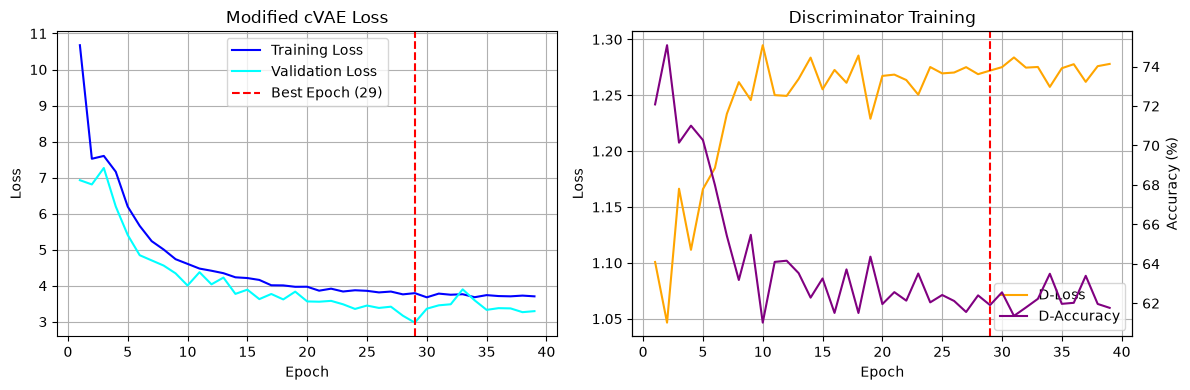

In [14]:
# Define epoch numbers for plotting
epochs = np.arange(1, len(modified_train_losses) + 1)

# Create plots for modified cVAE and discriminator training
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

# Plot modified cVAE training and validation loss
ax1.plot(epochs, modified_train_losses, label='Training Loss', color='blue')
ax1.plot(epochs, modified_val_losses, label='Validation Loss', color='cyan')
ax1.axvline(x=best_modified_epoch, color='red', linestyle='--', label=f'Best Epoch ({best_modified_epoch})')
ax1.set_title('Modified cVAE Loss')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.legend()
ax1.grid(True)

# Plot discriminator loss
ax2.plot(epochs, discriminator_train_losses, label='D-Loss', color='orange')
ax2.axvline(x=best_modified_epoch, color='red', linestyle='--')
ax2.set_title('Discriminator Training')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Loss')
ax2.grid(True)

# Plot discriminator accuracy on a separate y-axis
ax3 = ax2.twinx()
ax3.plot(epochs, discriminator_train_acc, label='D-Accuracy', color='purple')
ax3.set_ylabel('Accuracy (%)')

# Combine discriminator legends
lines1, labels1 = ax2.get_legend_handles_labels()
lines2, labels2 = ax3.get_legend_handles_labels()
ax2.legend(lines1 + lines2, labels1 + labels2)

# Save and display the plots
plt.tight_layout()
plt.savefig('assets/modified_vae_training.png', dpi=300, bbox_inches='tight')
plt.show()

In [15]:
# Combine the training and validation data for final model training
full_train_dataset = TensorDataset(data_custom['train_images'], data_custom['train_labels'])
full_train_dataloader = DataLoader(full_train_dataset, batch_size=batch_size, shuffle=True, num_workers=0)

print(f"Final training samples: {len(full_train_dataset)}")
print(f"Final training batches: {len(full_train_dataloader)}")

Final training samples: 60000
Final training batches: 60


In [16]:
# Reset random seeds before final baseline training
torch.manual_seed(seed)
np.random.seed(seed)
torch.cuda.manual_seed_all(seed)

# Recreate the baseline cVAE for final training
base_vae = cVAE(z_dim=z_dim, num_classes=num_classes).to(device)

opt_base = optim.AdamW(
    base_vae.parameters(),
    lr=0.001,
    eps=1e-5,
    fused=False,
    betas=(0.75, 0.99)
)

# Train the baseline cVAE on the full training set
for epoch in range(best_base_epoch):
    base_vae.train()
    train_loss = 0.0

    for batch in tqdm(full_train_dataloader, desc=f"Epoch {epoch+1}/{best_base_epoch} - Train"):
        x, cond = get_batch(batch, device)

        opt_base.zero_grad()

        x_hat, mu, logvar = base_vae(x, cond)
        loss, _, _ = compute_vae_loss(x, x_hat, mu, logvar)

        loss.backward()
        opt_base.step()

        train_loss += loss.item()

    train_loss /= len(full_train_dataloader)

    print(f"Epoch {epoch+1}: Train Loss = {train_loss:.4f}")

# Save the final baseline cVAE weights
torch.save(base_vae.state_dict(), 'assets/base_vae_weights.pt')

Epoch 1/125 - Train: 100%|██████████| 60/60 [00:00<00:00, 76.25it/s]


Epoch 1: Train Loss = 9.1565


Epoch 2/125 - Train: 100%|██████████| 60/60 [00:00<00:00, 63.50it/s]


Epoch 2: Train Loss = 5.4546


Epoch 3/125 - Train: 100%|██████████| 60/60 [00:00<00:00, 76.58it/s]


Epoch 3: Train Loss = 4.6480


... (240 outputs left out)

Epoch 124/125 - Train: 100%|██████████| 60/60 [00:00<00:00, 63.24it/s]


Epoch 124: Train Loss = 2.1858


Epoch 125/125 - Train: 100%|██████████| 60/60 [00:00<00:00, 76.38it/s]

Epoch 125: Train Loss = 2.1841


In [17]:
# Recreate the modified cVAE
torch.manual_seed(seed)
np.random.seed(seed)
torch.cuda.manual_seed_all(seed)
modified_vae = cVAE(z_dim=z_dim, num_classes=num_classes).to(device)

# Recreate the discriminator
torch.manual_seed(seed)
np.random.seed(seed)
torch.cuda.manual_seed_all(seed)
discriminator = cDiscriminator(num_classes=num_classes).to(device)


opt_modified = optim.AdamW(
    modified_vae.parameters(),
    lr=0.001,
    eps=1e-5,
    fused=False,
    betas=(0.75, 0.99)
)

opt_discriminator = optim.AdamW(
    discriminator.parameters(),
    lr=0.001,
    eps=1e-5,
    fused=False,
    betas=(0.75, 0.99)
)

# Train the modified cVAE and discriminator on the full training set
for epoch in range(best_modified_epoch):
    modified_vae.train()
    discriminator.train()

    train_loss = 0.0
    discriminator_loss = 0.0

    for batch in tqdm(full_train_dataloader, desc=f"Epoch {epoch+1}/{best_modified_epoch} - Train"):
        x, cond = get_batch(batch, device)

        # Generate reconstructed images
        x_hat, mu, logvar = modified_vae(x, cond)

        # Train the discriminator
        real_pred = discriminator(x, cond)
        fake_pred = discriminator(x_hat.detach(), cond)

        d_loss_real = adversarial_loss(real_pred, torch.ones_like(real_pred))
        d_loss_fake = adversarial_loss(fake_pred, torch.zeros_like(fake_pred))
        d_loss = d_loss_real + d_loss_fake

        opt_discriminator.zero_grad()
        d_loss.backward()
        opt_discriminator.step()

        # Train the modified cVAE
        fake_pred = discriminator(x_hat, cond)

        vae_loss, _, _ = compute_vae_loss(x, x_hat, mu, logvar)
        g_loss = adversarial_loss(fake_pred, torch.ones_like(fake_pred))
        loss = vae_loss + g_loss

        opt_modified.zero_grad()
        loss.backward()
        opt_modified.step()

        train_loss += loss.item()
        discriminator_loss += d_loss.item()

    train_loss /= len(full_train_dataloader)
    discriminator_loss /= len(full_train_dataloader)

    print(
        f"Epoch {epoch+1}: "
        f"Train Loss = {train_loss:.4f}, "
        f"Discriminator Loss = {discriminator_loss:.4f}"
    )

# Save the final modified cVAE and discriminator weights
torch.save(modified_vae.state_dict(), 'assets/modified_vae_weights.pt')
torch.save(discriminator.state_dict(), 'assets/discriminator_weights.pt')

Epoch 1/29 - Train: 100%|██████████| 60/60 [00:01<00:00, 35.74it/s]


Epoch 1: Train Loss = 10.3221, Discriminator Loss = 1.0928


Epoch 2/29 - Train: 100%|██████████| 60/60 [00:01<00:00, 39.58it/s]


Epoch 2: Train Loss = 7.7242, Discriminator Loss = 1.0111


Epoch 3/29 - Train: 100%|██████████| 60/60 [00:01<00:00, 39.61it/s]


Epoch 3: Train Loss = 7.3822, Discriminator Loss = 1.0790


... (48 outputs left out)

Epoch 28/29 - Train: 100%|██████████| 60/60 [00:01<00:00, 39.55it/s]


Epoch 28: Train Loss = 3.7499, Discriminator Loss = 1.2717


Epoch 29/29 - Train: 100%|██████████| 60/60 [00:01<00:00, 35.73it/s]

Epoch 29: Train Loss = 3.7517, Discriminator Loss = 1.2783


## Reconstruction Comparison

To qualitatively compare the two models, the same test images are passed through both the baseline and modified cVAE, and their reconstructions are displayed side by side:

- **Row 1 (Original)**: Ground-truth test images
- **Row 2 (Baseline)**: Reconstructions produced by the standard cVAE
- **Row 3 (Modified)**: Reconstructions produced by the cVAE trained with the additional discriminator-based loss

This comparison provides a qualitative assessment of reconstruction quality, particularly the sharpness and clarity of digit edges and strokes. Differences between the baseline and modified reconstructions are examined to determine whether the discriminator-based loss improves image sharpness, as proposed in the hypothesis.

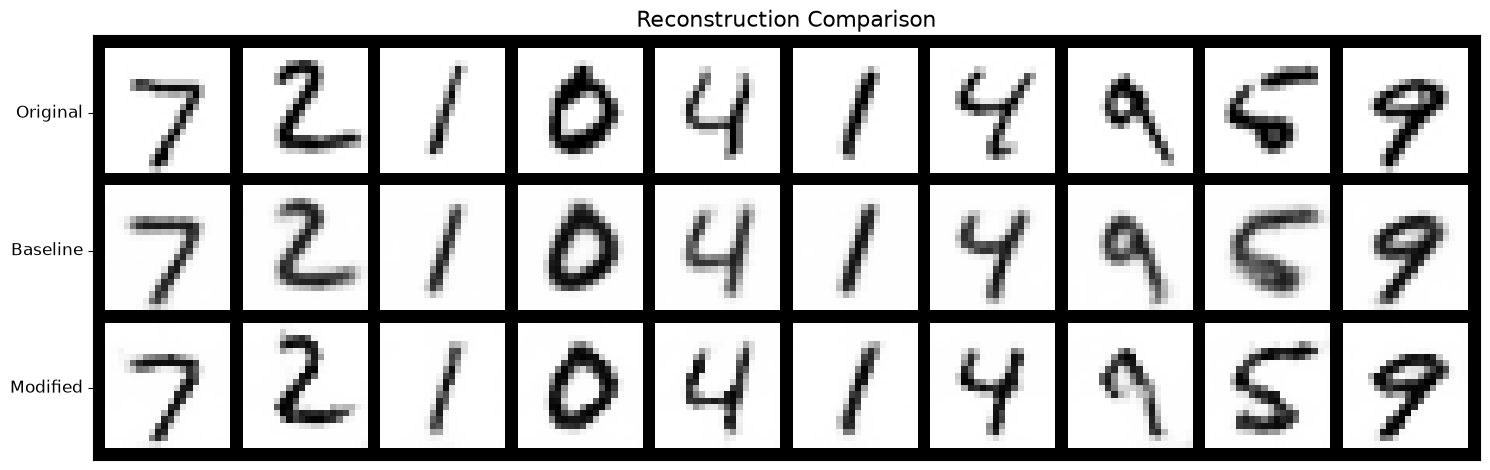

In [18]:
# Compare original, baseline and modified cVAE reconstructions
base_vae.eval()
modified_vae.eval()

# Get the same test images for both models
batch = next(iter(test_dataloader))
x_test, cond_test = get_batch(batch, device, f_train=False)

with torch.no_grad():
    # Reconstruct test images using the latent mean
    base_mu, _ = base_vae.encode(x_test, cond_test)
    base_x_hat = base_vae.decode(base_mu, cond_test)

    modified_mu, _ = modified_vae.encode(x_test, cond_test)
    modified_x_hat = modified_vae.decode(modified_mu, cond_test)

# Display original images and reconstructions
n_display = 10
display_images = torch.cat((
    x_test[:n_display],
    base_x_hat[:n_display],
    modified_x_hat[:n_display]
))

grid = make_grid(display_images, nrow=n_display).permute(1, 2, 0).cpu().numpy()

plt.figure(figsize=(15, 6))
plt.imshow(grid, cmap='gray')
plt.yticks([12, 34, 56], ['Original', 'Baseline', 'Modified'], rotation=0, va='center', fontsize=12)
plt.xticks([])
plt.title('Reconstruction Comparison', fontsize=16)
plt.tight_layout()
plt.savefig('assets/reconstruction_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

## Conditional Generation Comparison

For each of the 10 digit classes (0–9), 12 samples are generated from both models using the **same random latent vectors $z$** and corresponding class conditions. Using identical latent vectors enables a direct comparison between the baseline and modified cVAE under the same sampling conditions.

- **Left half (columns 1–12)**: Samples generated by the baseline cVAE
- **Right half (columns 13–24)**: Samples generated by the modified cVAE
- **Black separator line**: Separates the outputs of the two models

The generated samples are qualitatively compared in terms of:
- **Quality**: Overall visual quality of the generated digits
- **Sharpness**: Clarity and definition of digit edges and strokes
- **Consistency**: Whether the generated digits match their conditioned class
- **Variety**: Variation among generated samples within the same class

This comparison is used to examine whether introducing the discriminator-based loss improves the sharpness of conditionally generated images while maintaining consistency and variety.

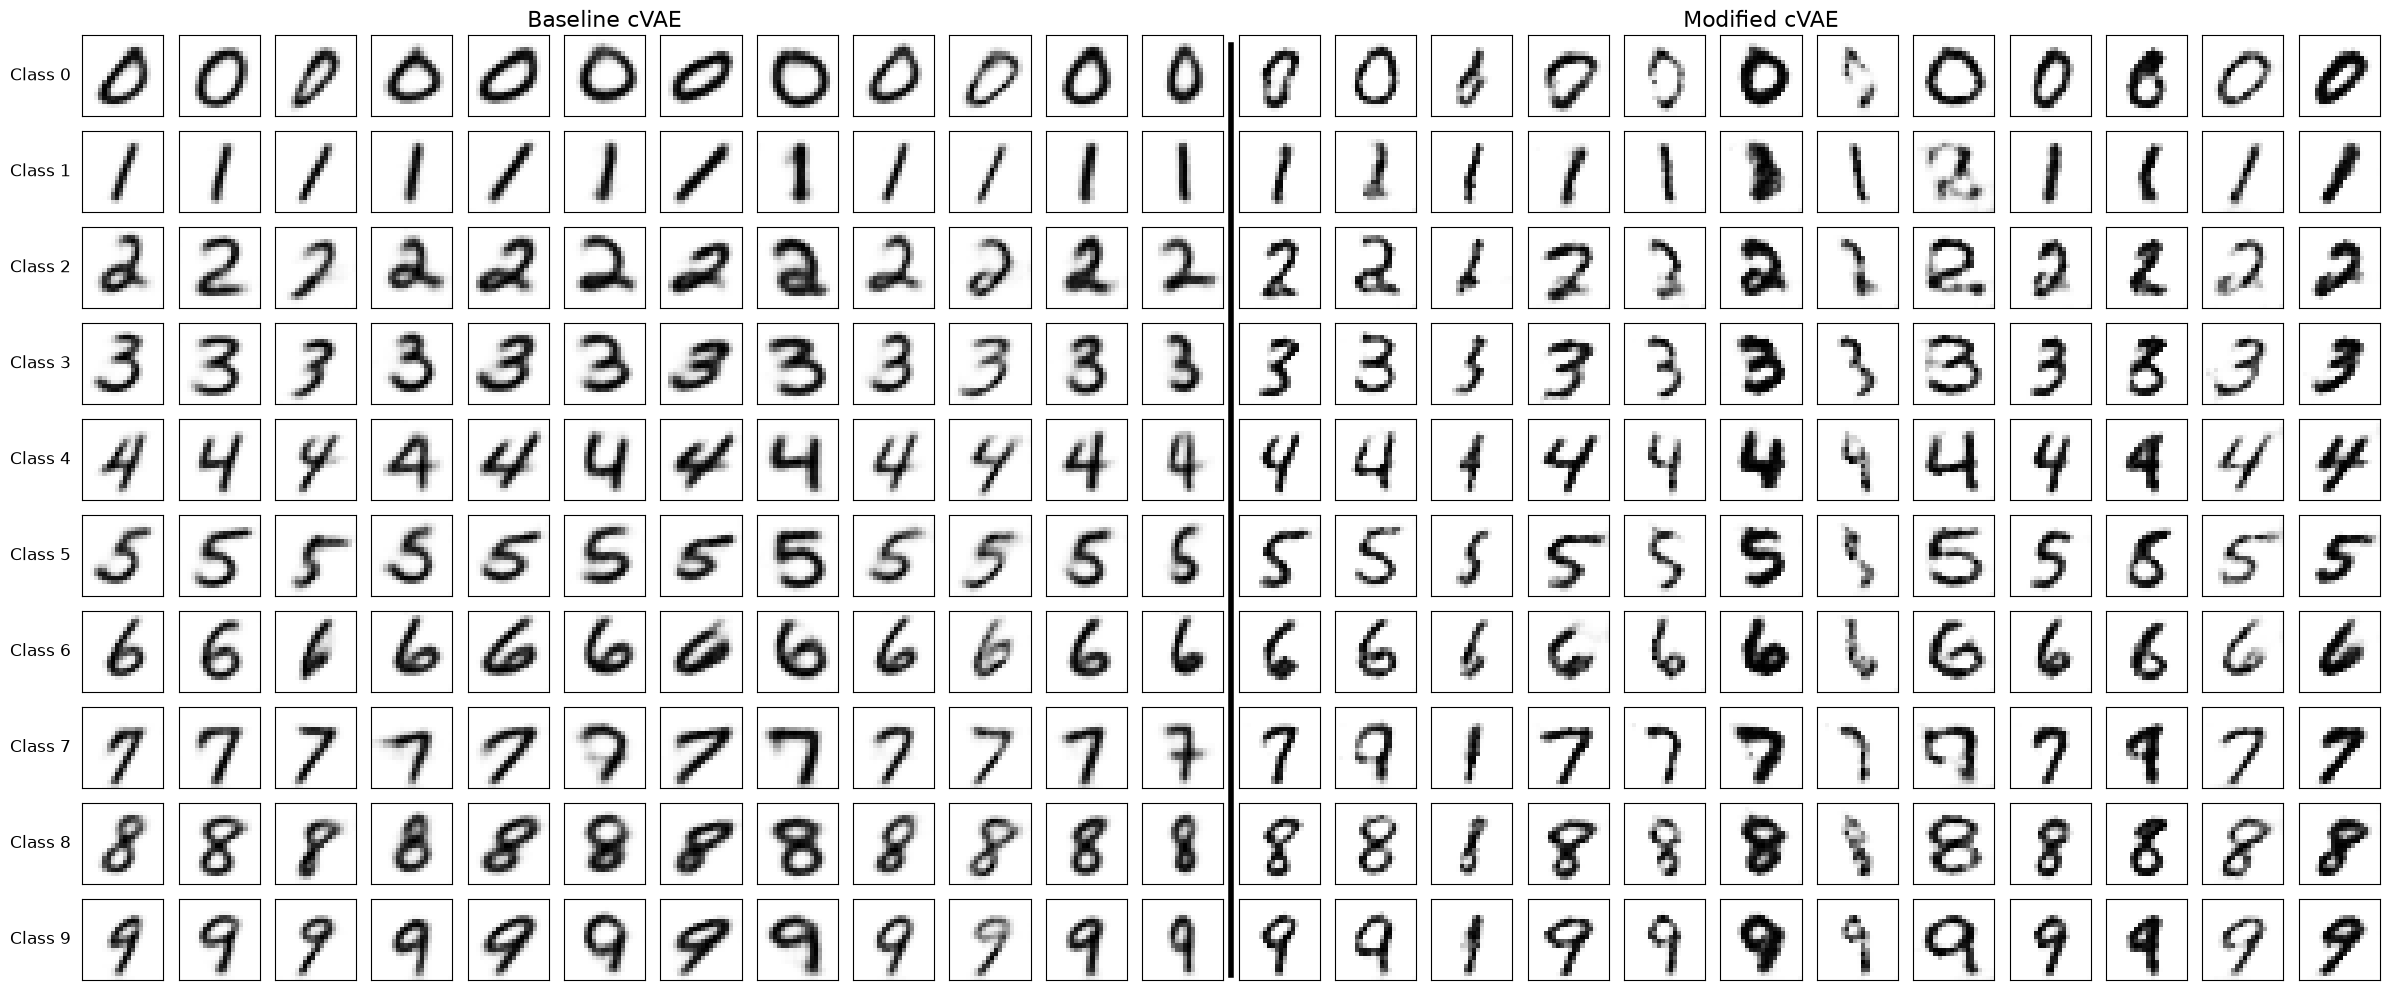

In [19]:
# Generate the same latent vectors for both models
num_samples = 12
z_samples = torch.randn(num_samples, z_dim).to(device)

# Generate 12 conditional samples for each digit class
def get_gen_grid(model, z_samples):
    model.eval()
    all_xhat = []

    with torch.no_grad():
        for c in range(num_classes):
            cond = F.one_hot(
                torch.tensor([c] * num_samples, device=device),
                num_classes=num_classes
            ).float()

            x_hat = model.decode(z_samples, cond)
            all_xhat.append(x_hat.cpu())

    return torch.stack(all_xhat)

# Generate samples from both models using the same latent vectors
base_gen_grid = get_gen_grid(base_vae, z_samples)
modified_gen_grid = get_gen_grid(modified_vae, z_samples)

# Display baseline and modified samples side by side
fig, axes = plt.subplots(num_classes, num_samples * 2, figsize=(24, 10))

for c in range(num_classes):
    for i in range(num_samples):
        # Display baseline cVAE samples
        axes[c, i].imshow(base_gen_grid[c, i].squeeze(), cmap='gray')
        axes[c, i].set_xticks([])
        axes[c, i].set_yticks([])

        if i == 0:
            axes[c, i].set_ylabel(
                f'Class {c}',
                rotation=0,
                labelpad=30,
                va='center',
                fontsize=12
            )

        # Display modified cVAE samples
        axes[c, i + num_samples].imshow(
            modified_gen_grid[c, i].squeeze(),
            cmap='gray'
        )
        axes[c, i + num_samples].set_xticks([])
        axes[c, i + num_samples].set_yticks([])

# Add model titles
axes[0, 5].set_title('Baseline cVAE', fontsize=16)
axes[0, 17].set_title('Modified cVAE', fontsize=16)

plt.tight_layout()

# Add a separator between baseline and modified samples
import matplotlib.lines as lines

left_pos = axes[0, num_samples - 1].get_position()
right_pos = axes[0, num_samples].get_position()
mid_x = (left_pos.x1 + right_pos.x0) / 2

line = lines.Line2D(
    [mid_x, mid_x],
    [0.02, 0.95],
    transform=fig.transFigure,
    color='black',
    linewidth=4
)
fig.add_artist(line)

# Save and display the comparison
plt.savefig(
    'assets/conditional_generation_comparison.png',
    dpi=300,
    bbox_inches='tight'
)
plt.show()